# Lab 10: How LangChain and LangGraph run the same agent

## Goal

Rebuild the shop's support-desk agent with LangChain's `create_agent`, see that what it returns is a LangGraph graph,
build that same graph by hand, then make the agent stop before it files a refund and wait for a person's approval,
also across a kernel restart. Two moments teach it. The agent answers correctly, but its answer's `content` is a
list of blocks, not a string, so the `.content.lower()` that worked on a plain model call crashes on it: the
framework chose a different API for us. And after a restart, a paused run kept only in memory is gone; resuming it
raises no error, and the model, now holding no request at all, can propose a refund nobody asked for.

## What you will learn

- How to construct LangChain's `ChatOpenAI` from `models.env`, call it directly and read the `AIMessage` it returns
  (`content`, `text`, `usage_metadata`, `response_metadata`).
- How to turn plain Python functions into LangChain tools with `tool` and build the desk agent with `create_agent`.
- Why the agent's answer arrives as a list of content blocks, and how `.text` reads every reply the same way.
- What `create_agent` returns, a LangGraph `CompiledStateGraph`, and how to build the same graph by hand with
  `StateGraph`: the state, the `add_messages` reducer, the nodes, the routing function and the back edge.
- How to ask the agent for a typed answer with `response_format`.
- How to pause before a write with `HumanInTheLoopMiddleware`, resume with `Command`, and why only a checkpointer that
  writes to a file (`SqliteSaver`) keeps a paused run across a restart.

## Where this lab starts

Lab 03 wrote the agent loop by hand: send the messages and the tool schemas, run every tool the model asks for,
append the results, and repeat until the model answers in text. Lab 07 ran the same loop in the OpenAI Agents SDK.
This lab runs it in two open-source frameworks that work together:

- **LangChain** (the `langchain`, `langchain-core` and `langchain-openai` packages) gives the building blocks, a chat
  model object, message objects and tools, and `create_agent`, a prebuilt agent loop.
- **LangGraph** (the `langgraph` package) is the engine underneath. It runs a program written as a **graph**: a
  **state** (a dictionary every step can read and update), **nodes** (Python functions that each return an update)
  and **edges** (which node runs next). A **checkpointer** can save the state after every step.

We use the same three lookups on the shop's database and the same question as lab 03, so the only thing that
changes is who runs the loop. The notebook defines everything it uses and runs on its own.

The picture is the graph this lab builds. Read it from the left: the state, which holds the conversation, enters at
START; the model node calls the model; a routing function of ours decides whether the reply asks for tools; if it
does, the tools node runs them and the back edge returns to the model; if not, the run ends with the answer last. The
black box is the model's work; the lime boxes run our Python.

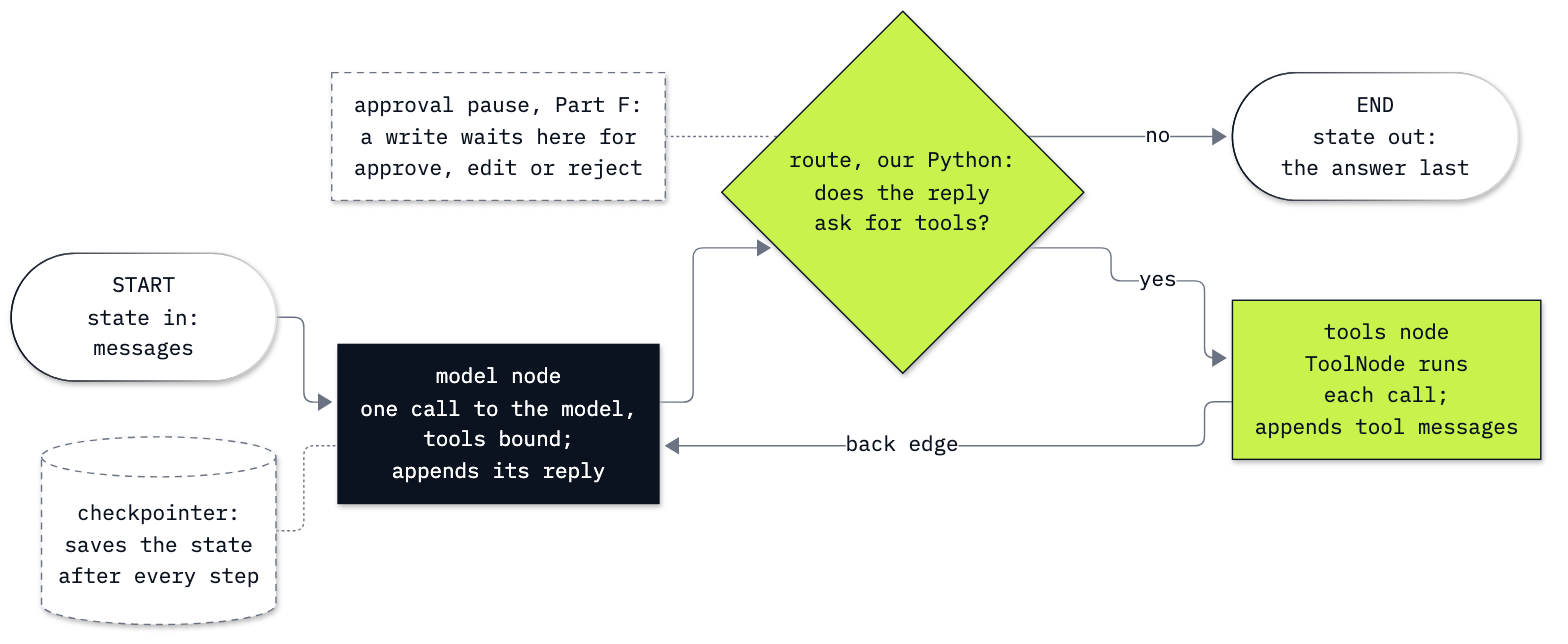

In [1]:
from IPython.display import Image

Image("resources/lab10_graph_by_hand.png", width=760)

Notice the two dashed boxes: neither is a step of the loop. The approval pause (Part F) stops the run between the
model's request and the tool, and the checkpointer (Parts F and G) is what lets a stopped run continue later.

---

## Setup

The config cell is the same in every lab: it finds the repository folder by `models.env`, reads the model and the
prices from there, and finds your key without printing it (Lab 00 reads it line by line).

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Call a LangChain chat model directly

Every LangChain agent is built around a chat model object. Before we give one to an agent, we construct it, call it
once and read what comes back, so the objects the agent passes around later are familiar.

`ChatOpenAI`, from the `langchain-openai` package, wraps the OpenAI client. We give it two settings from `models.env`:

- `model=MODEL`: the model name.
- `reasoning_effort=EFFORT`: the reasoning effort, `none` here. When `models.env` sets no effort, `EFFORT` is
  `None`, and `ChatOpenAI` leaves the setting out of the request, as `omit` did in the labs that call the OpenAI
  library directly.

Constructing the object makes no call; it only stores the settings.

In [3]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT)
print(type(llm).__name__, "| model:", llm.model_name, "| reasoning effort:", llm.reasoning_effort)

ChatOpenAI | model: gpt-6-luna | reasoning effort: none


Now one call. In LangChain a conversation is a list of **message objects**: `SystemMessage` holds the instructions
and `HumanMessage` what the user typed. Later we will meet `AIMessage` (a reply from the model) and `ToolMessage` (a
tool's result). `invoke` sends the list and returns the model's reply.

In [4]:
from langchain_core.messages import HumanMessage, SystemMessage

messages = [
    SystemMessage("You help the support reps of a music shop. Answer in one sentence."),
    HumanMessage("What should a rep check before refunding a duplicate charge?"),
]
reply = llm.invoke(messages)
print(type(reply).__name__)

AIMessage


The reply is an `AIMessage`. It carries more than the words; we print the fields we will use in this lab one by one.

In [5]:
print("content:       ", repr(reply.content))
print("text:          ", reply.text)
print("usage_metadata:", reply.usage_metadata)
print("finish_reason: ", reply.response_metadata["finish_reason"])
print("response id:   ", reply.response_metadata["id"])

content:        'Before refunding, confirm that both charges were actually posted (not a pending authorization), match the same order and amount, and that one hasn’t already been refunded or disputed.'
text:           Before refunding, confirm that both charges were actually posted (not a pending authorization), match the same order and amount, and that one hasn’t already been refunded or disputed.
usage_metadata: {'input_tokens': 37, 'output_tokens': 38, 'total_tokens': 75, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}
finish_reason:  stop
response id:    chatcmpl-Eebgxxq7do3D2rnZShYU3nPKjsw0c


Reading the fields:

- `content` is a **string** (`repr` shows its quotes): *Before refunding, confirm that both charges were actually posted (not a pending authorization), match the same order and amount, and that one hasn’t already been refunded or disputed.*
- `text` is the same words. For this reply the two are equal; Part C shows a reply where they are not.
- `usage_metadata` counts the tokens: 37 in (the system message and the question) and 38 out.
  `output_token_details` shows no reasoning tokens, as expected with effort `none`.
- `response_metadata` holds what the API itself returned. `finish_reason` is `stop`, as in lab 03: the model wrote
  text. The `id` starts with `chatcmpl-`: the call went to OpenAI's **Chat Completions** API, the API labs 01 to 06
  use. Keep that prefix in mind for Part C.

**Checkpoint A.** An `AIMessage` whose `content` is a `str`, a `finish_reason` of `stop` and an `id` that starts with
`chatcmpl-`. A pass shows how LangChain wraps one call; nothing in it is an agent yet.

---

## Part B: Build the desk agent with `create_agent`

An agent needs tools. Ours are the same three lookups lab 03 used, on the shop's database `data/chinook.db`, opened
read-only (`mode=ro` in the connection's address, so no lookup can change it) and with `check_same_thread=False`,
because LangGraph runs tools on worker threads. Each lookup is a plain Python function that runs one SQL query. This
time each one has **type hints** (`name: str`, `-> list`) and a **docstring**, because LangChain reads both to
describe the tool to the model:

- `find_customer(name)` matches the full name exactly and returns a list, because two customers could share a name.
- `get_invoices(customer_id)` counts the customer's invoices and adds up their totals.
- `get_support_rep(customer_id)` names the employee who looks after the customer.

In [6]:
import json
import sqlite3

DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list:
    """Find a shop customer by full name. Returns a list of matches with their customer_id."""
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0]}

Before any model is involved, we call the three lookups ourselves for the customer this lab asks about, Helena Holý.
These are the right answers every run below is checked against.

In [7]:
print(find_customer("Helena Holý"))
print(get_invoices(6))
print(get_support_rep(6))

[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


Helena Holý is customer **6**, with **7 invoices** adding up to **49.62** US dollars, and her rep is **Steve
Johnson**. The second and third lookups need the `customer_id` that only the first returns, so the model has to call
`find_customer` first and wait for its result.

### Turn the functions into tools

In lab 03 we wrote each tool's JSON schema by hand. LangChain's `tool` writes it from the function: the name from the
function's name, the description from the docstring, the parameters from the type hints. `tool` is a **decorator**:
writing `@tool` on the line above `def find_customer` would be the same as `find_customer = tool(find_customer)`. We
call it as a function instead, so the plain functions keep their names and stay available for Part D.

`convert_to_openai_tool` shows the schema LangChain will send for a tool, in Chat Completions' format.

In [8]:
from langchain.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool

TOOLS = [tool(find_customer), tool(get_invoices), tool(get_support_rep)]
print(type(TOOLS[0]).__name__, "|", TOOLS[0].name, "|", TOOLS[0].description)
print(json.dumps(convert_to_openai_tool(TOOLS[0]), indent=2))

StructuredTool | find_customer | Find a shop customer by full name. Returns a list of matches with their customer_id.
{
  "type": "function",
  "function": {
    "name": "find_customer",
    "description": "Find a shop customer by full name. Returns a list of matches with their customer_id.",
    "parameters": {
      "properties": {
        "name": {
          "type": "string"
        }
      },
      "required": [
        "name"
      ],
      "type": "object"
    }
  }
}


`tool` returned a `StructuredTool`, LangChain's tool object, named `find_customer` and described by the docstring. Its
schema has the shape lab 03 wrote by hand: a name, a description and one required string parameter, `name`, read
from the hint `name: str`. This printed schema has no `strict` or `additionalProperties` field. That tells us what
this conversion returns, not what the server enforces. This model's tool requests use Responses, which can normalize
a compatible schema into strict mode when `strict` is omitted. Chat Completions has a different default. Lab 03
made the request explicit; here we should not infer validation guarantees from the missing field. See the
[API's strict-mode rules](https://developers.openai.com/api/docs/guides/function-calling#strict-mode).

### Build the agent

`create_agent` takes the model, the tools and a system prompt, and returns the loop lab 03 wrote, ready to run. The
system prompt is lab 03's: Chinook is a public sample database, and a model may have seen Helena's numbers in its
training data, so we ask for every fact to come from a lookup.

In [9]:
from langchain.agents import create_agent

SYSTEM = ("You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. "
          "Answer in one or two sentences.")
agent = create_agent(llm, TOOLS, system_prompt=SYSTEM)
print(type(agent).__name__)
print(list(agent.get_graph().nodes))

CompiledStateGraph
['__start__', 'model', 'tools', '__end__']


The agent is a `CompiledStateGraph`: a LangGraph graph, compiled and ready to run. It has four nodes:

- `__start__` and `__end__` are where the state enters and leaves; they run no code of ours.
- `model` calls the chat model with the tools.
- `tools` runs the tools the model asks for.

`get_graph()` describes the graph's nodes and edges, and `draw_mermaid()` writes that description as Mermaid text, a
small language for diagrams.

In [10]:
print(agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



Read the lines with arrows; the rest is layout and colour:

- `__start__ --> model`: a **solid** arrow always runs. Every run starts with a model call.
- `model -.-> tools` and `model -.-> __end__`: **dotted** arrows are conditional. After the model node, a function
  looks at the reply and picks one: the tools if it asks for any, the end if not.
- `tools -.-> model`: the **back edge**, which makes the loop. It is dotted because `create_agent`'s function could
  also end the run after a tool marked `return_direct`; none of ours is, so it always returns to the model.

LangGraph can turn this text into a picture itself: `draw_mermaid_png()` sends it to the mermaid.ink web service,
and `draw_png()` needs the `pygraphviz` package, which this repository does not install. We drew the same text ahead of
time instead, unchanged apart from the colours (the model node black, the tools node lime), so this notebook needs no
extra service:

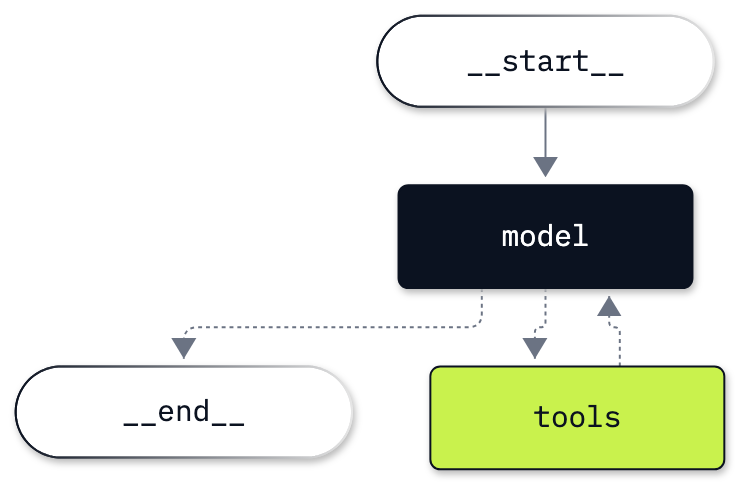

In [11]:
Image("resources/lab10_create_agent_graph.png", width=420)

### Ask Helena's question

The graph's input is its state: a dictionary with one key, `messages`. We send one message, written as a dictionary
with a `role` and `content` (LangChain turns it into a `HumanMessage`). The system prompt is not part of the state:
`create_agent` adds it in front of the messages on every model call.

In [12]:
QUESTION = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"
result = agent.invoke({"messages": [{"role": "user", "content": QUESTION}]})
print(type(result).__name__, list(result), len(result["messages"]), "messages")

dict ['messages'] 7 messages


The result is the state after the run: still a dictionary with the key `messages`, which now holds the whole
conversation, 7 messages. Each message has a `type`: `human`, `ai` (a reply from the model) or `tool`. We
print every message before the last: for an `ai` message, the tools it asked for; for the others, their content.

In [13]:
for message in result["messages"][:-1]:
    if message.type == "ai":
        print("ai     asks for", [(call["name"], call["args"]) for call in message.tool_calls])
    else:
        print(f"{message.type:6}", message.content)

human  How many invoices does Helena Holý have, what do they add up to, and who is her support rep?
ai     asks for [('find_customer', {'name': 'Helena Holý'})]
tool   [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
ai     asks for [('get_invoices', {'customer_id': 6}), ('get_support_rep', {'customer_id': 6})]
tool   {"customer_id": 6, "invoice_count": 7, "total": 49.62}
tool   {"customer_id": 6, "support_rep": "Steve Johnson"}


The same run as lab 03's loop, step by step:

1. `human`: our question.
2. `ai`: the model asks for `find_customer` with Helena's name. `tool_calls` is a list of dictionaries with the
   tool's `name` and its `args`, already parsed from JSON.
3. `tool`: the tools node ran it; Helena is customer 6.
4. `ai`: two calls in one reply, `get_invoices` and `get_support_rep`, both with customer 6.
5. `tool` twice: one result per call.

That is three model calls, as in lab 03: the loop we wrote there, run by the framework. Now the last message, the
answer:

In [14]:
answer = result["messages"][-1]
print(answer.content)

[{'type': 'text', 'text': 'Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.', 'annotations': [], 'id': 'msg_050b6e600d1684be006ae44ca0a9f087d2a9a633593004214b', 'phase': 'final_answer'}]


The facts are right: 7 invoices, 49.62 US dollars and Steve Johnson. But look at what was printed: not a sentence, but a list holding one
dictionary, with the sentence under the key `text`. Part C finds out why.

**Checkpoint B.** Nodes `['__start__', 'model', 'tools', '__end__']`; `find_customer` first, then `get_invoices` and
`get_support_rep` in one reply; an answer with 7 invoices, 49.62 US dollars and Steve Johnson. A pass shows
`create_agent` runs lab 03's loop on our tools; the printed list shows its answer is not the plain string Part A
returned.

---

## Part C: Read the agent's answer from content blocks

Code that uses an answer usually treats it as text: it lowercases it before a check, searches it or stores it. On
Part A's reply, string methods work. We try the same `.content.lower()` on both.

In [15]:
print("Part A's reply:    ", type(reply.content).__name__, "->", reply.content.lower())
try:
    print("the agent's answer:", type(answer.content).__name__, "->", answer.content.lower())
except AttributeError as error:
    print("the agent's answer:", type(answer.content).__name__, "-> AttributeError:", error)

Part A's reply:     str -> before refunding, confirm that both charges were actually posted (not a pending authorization), match the same order and amount, and that one hasn’t already been refunded or disputed.
the agent's answer: list -> AttributeError: 'list' object has no attribute 'lower'


The same line that works on Part A's reply crashes on the agent's answer: `AttributeError: 'list' object has no attribute
'lower'`. `.lower()` is a string method, and the agent's `content` is a **list**. (`try` and `except AttributeError`
catch the error so that we can print it and carry on; without them the cell would stop with the same message.)

What is in the list, and why? We print its one item and the response id.

In [16]:
print(len(answer.content), "block")
print(answer.content[0])
print("response id:", answer.response_metadata["id"])

1 block
{'type': 'text', 'text': 'Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.', 'annotations': [], 'id': 'msg_050b6e600d1684be006ae44ca0a9f087d2a9a633593004214b', 'phase': 'final_answer'}
response id: resp_050b6e600d1684be006ae44ca014ec87d294c92fb79aaae91c


The list holds one **content block**, a dictionary:

- `type`: `text`, a block of words (other types hold tool calls, reasoning or images);
- `text`: the answer itself;
- `annotations`: citations, empty here;
- `id` and `phase`: the API's own label for this output and its stage, `final_answer`.

And the response id starts with `resp_`, not `chatcmpl-`: this call went to OpenAI's **Responses API**, the newer API
that returns a list of output items. We never asked for it. `ChatOpenAI` chooses the API for each call: with no
tools it used Chat Completions in Part A; for the model in `models.env`, a request that carries tools goes to the
Responses API, and LangChain keeps the list of blocks as `content`. The rule depends on the model's name, so changing
`models.env` to another model could put the agent back on Chat Completions and turn `content` into a string again:
code that reads `.content` would then work with one model and crash with the other.

The model's earlier replies, the ones that asked for tools, are lists too, holding the calls:

In [17]:
first_reply = result["messages"][1]
print(first_reply.content)
print("text:", repr(first_reply.text))

[{'arguments': '{"name":"Helena Holý"}', 'call_id': 'call_NqWEZ0fCwh2kDrkmOxJZ1UVK', 'name': 'find_customer', 'type': 'function_call', 'id': 'fc_050b6e600d1684be006ae44c9d775087d2bb121fd528021478', 'status': 'completed'}]
text: ''


That block's `type` is `function_call`, the Responses API's tool call; LangChain also parsed it into `tool_calls`, as
Part B printed. Its `.text` is an empty string: the reply has no words.

### `.text` reads every reply the same way

`.text` joins the text blocks of a reply into one string, whatever the API returned. On Part A's string it gives the
string back. So it is the one way to read words that works for both replies:

In [18]:
print("Part A's reply:    ", reply.text)
print("the agent's answer:", answer.text)
print("names the rep:", "steve johnson" in answer.text.lower())

Part A's reply:     Before refunding, confirm that both charges were actually posted (not a pending authorization), match the same order and amount, and that one hasn’t already been refunded or disputed.
the agent's answer: Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.
names the rep: True


Both replies now read as strings, and the check finds the rep's name in the agent's answer.

**Key lesson:** read a reply's words with `.text` and its tool requests with `.tool_calls`, never with string methods
on `.content`. `.content` is what the provider's API returned and can be a string or a list. (`.content_blocks` gives
the same blocks in LangChain's standard form, the same for every provider, when you need more than the words. If you
want one API every time, `ChatOpenAI(..., use_responses_api=True)` sends every call to Responses.)

**Checkpoint C.** `list` and `AttributeError: 'list' object has no attribute 'lower'`; one block of type `text`; a
response id starting with `resp_`; `.text` gives the answer and `names the rep: True`. A pass shows where the answer
lives; it does not show the facts came from the tools, which Part B's message list does.

---

## Part D: Build the same graph by hand in LangGraph

`create_agent` gave us a graph with a model node, a tools node, a condition and a back edge. To see what each piece
does, and to be able to put steps of our own between them, we write the graph ourselves with LangGraph's
`StateGraph`. Three ideas, one at a time: how a node's update is merged into the state, a graph with no model, then
the model loop.

### How a node's update is merged: the reducer

A node returns only the keys it changed, and LangGraph merges that update into the state. For most keys, merging
**replaces** the old value. For a conversation that would be wrong: a model node that returns `{"messages":
[new_reply]}` would wipe out the history. So the `messages` key gets a **reducer**, a function that says how an
update is combined with what is there. LangGraph's `add_messages` appends the new messages, and replaces a message
only when the update carries one with the same `id`. It is a plain function, so we can call it on two small lists:

In [19]:
from langchain_core.messages import AIMessage
from langgraph.graph.message import add_messages

history = [HumanMessage("I need help with an invoice.", id="m1")]
update = [AIMessage("Of course. Which invoice?", id="m2")]
merged = add_messages(history, update)
print([(m.id, m.type, m.content) for m in merged])

[('m1', 'human', 'I need help with an invoice.'), ('m2', 'ai', 'Of course. Which invoice?')]


Two messages: the update was **appended** after the history. Now an update whose message has an `id` already in the
list:

In [20]:
correction = [AIMessage("Of course. Which invoice number?", id="m2")]
print([(m.id, m.type, m.content) for m in add_messages(merged, correction)])

[('m1', 'human', 'I need help with an invoice.'), ('m2', 'ai', 'Of course. Which invoice number?')]


Still two messages: `m2` was **replaced**, not added. That second rule is what lets a step correct a message: Part
F's approval step returns the waiting reply again, with the same `id` and its tool calls changed by the reviewer's
decision, and the reducer swaps it in. Without a reducer, both updates would have replaced the whole list.

### A graph with no model

The smallest useful graph, in five steps, with plain Python and no model:

1. **The state:** a `TypedDict` names the keys and their types. Ours has the customer's `name`, their `customer_id`
   and their `invoice_count`.
2. **The builder:** `StateGraph(LookupState)`.
3. **The nodes:** `add_node(name, function)`. Each function takes the state and returns an update.
4. **The edges:** `add_edge(a, b)` says `b` runs after `a`; `START` and `END` are the entry and the exit.
5. **Compile:** `compile()` checks the graph and returns the runnable object.

In [21]:
from typing_extensions import TypedDict
from langgraph.graph import END, START, StateGraph


class LookupState(TypedDict):
    name: str
    customer_id: int
    invoice_count: int


def find_node(state):
    return {"customer_id": find_customer(state["name"])[0]["customer_id"]}


def count_node(state):
    return {"invoice_count": get_invoices(state["customer_id"])["invoice_count"]}


builder = StateGraph(LookupState)
builder.add_node("find", find_node)
builder.add_node("count", count_node)
builder.add_edge(START, "find")
builder.add_edge("find", "count")
builder.add_edge("count", END)
lookup_graph = builder.compile()
print(type(lookup_graph).__name__, list(lookup_graph.get_graph().nodes))

CompiledStateGraph ['__start__', 'find', 'count', '__end__']


The same class as the agent, `CompiledStateGraph`, with our two nodes between `__start__` and `__end__`. We run it
with only the name in the state:

In [22]:
print(lookup_graph.invoke({"name": "Helena Holý"}))

{'name': 'Helena Holý', 'customer_id': 6, 'invoice_count': 7}


The state went in with one key and came out with three. `find` returned only `customer_id`, `count` only
`invoice_count`, and `name` survived both because LangGraph merged each update into the state. No model was involved:
a graph is a way to write a program, and calling a model is just one thing a node can do.

### The model node, the tools node and the route

Now the agent's graph. Its state has one key, `messages`, with `add_messages` as the reducer:
`Annotated[list, add_messages]` says the type is a list and attaches the reducer to it. Three pieces fill it:

1. **The model node** calls the model once. `llm.bind_tools(TOOLS)` returns a copy of our model that sends the three
   tool schemas with every call (in lab 03 we passed `tools=TOOLS` to each call). The node puts the system message in
   front of the state's messages, as `create_agent` does, and returns the reply as an update, which the reducer
   appends.
2. **The tools node** is LangGraph's `ToolNode(TOOLS)`. It runs every tool call in the last message and returns one
   `ToolMessage` per call: lab 03's `for call in tool_calls`.
3. **The route** is a plain Python function, run after the model node, that returns the name of the next node:
   `"tools"` if the last reply asks for any tool, `END` if not. It is lab 03's `if finish_reason != "tool_calls":
   break`, written as an edge; no model is called to decide. (LangGraph ships the same function as `tools_condition`.)

In [23]:
from typing import Annotated
from langgraph.prebuilt import ToolNode


class AgentState(TypedDict):
    messages: Annotated[list, add_messages]


model_with_tools = llm.bind_tools(TOOLS)


def model_node(state):
    reply = model_with_tools.invoke([SystemMessage(SYSTEM)] + state["messages"])
    return {"messages": [reply]}


def route(state):
    if state["messages"][-1].tool_calls:
        return "tools"
    return END

Now the edges. `add_conditional_edges("model", route, ["tools", END])` runs `route` after the model node and goes
wherever it points; the list names the places it may point to, so the drawing can show them. The fixed edge from
`tools` back to `model` is the loop: without it the graph would end after one round of tools.

In [24]:
builder = StateGraph(AgentState)
builder.add_node("model", model_node)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_edge(START, "model")
builder.add_conditional_edges("model", route, ["tools", END])
builder.add_edge("tools", "model")
hand_graph = builder.compile()
print(hand_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools --> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



The same nodes, and the same arrows from `model`. One line differs: `tools --> model` is solid here, because our
back edge is fixed, and dotted in `create_agent`'s graph, because its edge is a function that could also end the
run. We compare the two graphs' edges in code, as (from, to) pairs, leaving out the solid or dotted style:

In [25]:
def edges(graph):
    return sorted((edge.source, edge.target) for edge in graph.get_graph().edges)


print("by hand:     ", edges(hand_graph))
print("create_agent:", edges(agent))
print("✅ same nodes and edges" if edges(hand_graph) == edges(agent) else "❌ the graphs differ")

by hand:      [('__start__', 'model'), ('model', '__end__'), ('model', 'tools'), ('tools', 'model')]
create_agent: [('__start__', 'model'), ('model', '__end__'), ('model', 'tools'), ('tools', 'model')]
✅ same nodes and edges


The same four edges. The check reads only the graph's structure; whether the two run the same way is for the run to
show. Helena's question, on the graph we built:

In [26]:
hand_result = hand_graph.invoke({"messages": [{"role": "user", "content": QUESTION}]})
for message in hand_result["messages"][:-1]:
    if message.type == "ai":
        print("ai     asks for", [(call["name"], call["args"]) for call in message.tool_calls])
    else:
        print(f"{message.type:6}", message.content)
print("answer:", hand_result["messages"][-1].text)

human  How many invoices does Helena Holý have, what do they add up to, and who is her support rep?
ai     asks for [('find_customer', {'name': 'Helena Holý'})]
tool   [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
ai     asks for [('get_invoices', {'customer_id': 6}), ('get_support_rep', {'customer_id': 6})]
tool   {"customer_id": 6, "invoice_count": 7, "total": 49.62}
tool   {"customer_id": 6, "support_rep": "Steve Johnson"}
answer: Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


The same steps as Part B: `find_customer`, then `get_invoices` and `get_support_rep` in one reply, then the answer:
*Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.* We read it with `.text`: the model behind our hand-built node has tools bound too, so its reply is a list
of blocks as well.

So what does writing the graph yourself buy? Any step you like, anywhere: a node that checks a rule before the
tools run, a branch on a business condition, a fixed sequence with no model at all. When the job is the plain loop,
`create_agent` writes it for you, and its **middleware** (Part F) adds steps to it without writing the graph.

**Checkpoint D.** `add_messages` appends `m2`, then replaces it; the lookup graph returns `customer_id` 6 and
`invoice_count` 7; `✅ same nodes and edges`; the hand-built graph answers with 7 invoices, 49.62 US dollars and
Steve Johnson.

---

## Part E: Ask the agent for a typed answer

The answer is a sentence. Code that stores it, or checks the total, would have to pick numbers out of words. A
**typed answer** is an object with named fields instead. Here is the one we want for Helena, written by hand from
the lookups in Part B:

In [27]:
wanted = {"customer_name": "Helena Holý", "invoice_count": 7, "total_usd": 49.62, "support_rep": "Steve Johnson"}
print(wanted)

{'customer_name': 'Helena Holý', 'invoice_count': 7, 'total_usd': 49.62, 'support_rep': 'Steve Johnson'}


To ask the agent for that shape we describe it as a **Pydantic model**: a class that lists each field with its type
and checks values against them. `Field(description=...)` adds a sentence the model reads, so a description is an
instruction, not a comment. `model_json_schema()` shows the JSON schema built from the class, which is what the
model is sent.

In [28]:
from pydantic import BaseModel, Field


class DeskAnswer(BaseModel):
    """The facts a support rep asked for about one customer."""
    customer_name: str = Field(description="The customer's full name, as the database spells it")
    invoice_count: int
    total_usd: float = Field(description="What the customer's invoices add up to, in US dollars")
    support_rep: str


print(json.dumps(DeskAnswer.model_json_schema(), indent=2, ensure_ascii=False))

{
  "description": "The facts a support rep asked for about one customer.",
  "properties": {
    "customer_name": {
      "description": "The customer's full name, as the database spells it",
      "title": "Customer Name",
      "type": "string"
    },
    "invoice_count": {
      "title": "Invoice Count",
      "type": "integer"
    },
    "total_usd": {
      "description": "What the customer's invoices add up to, in US dollars",
      "title": "Total Usd",
      "type": "number"
    },
    "support_rep": {
      "title": "Support Rep",
      "type": "string"
    }
  },
  "required": [
    "customer_name",
    "invoice_count",
    "total_usd",
    "support_rep"
  ],
  "title": "DeskAnswer",
  "type": "object"
}


Four properties, all `required`, with the types from the class (`int` became `integer`, `float` became `number`) and
the two descriptions. `create_agent(..., response_format=DeskAnswer)` adds this schema to the agent: the loop runs as
before, and the model's last reply must be JSON that fits it. For a provider with its own structured output, as
OpenAI has, LangChain sends the schema with every model call as the format the reply's text must take, then reads the
last reply into a `DeskAnswer`, which checks each field's type.

In [29]:
typed_agent = create_agent(llm, TOOLS, system_prompt=SYSTEM, response_format=DeskAnswer)
typed_result = typed_agent.invoke({"messages": [{"role": "user", "content": QUESTION}]})
print(list(typed_result))
print("tools called:", [call["name"] for m in typed_result["messages"] if m.type == "ai" for call in m.tool_calls])

['messages', 'structured_response']
tools called: ['find_customer', 'get_invoices', 'get_support_rep']


The state has a second key now, `structured_response`, and the agent made the same lookups as before. The raw last
message beside the parsed object:

In [30]:
raw = typed_result["messages"][-1]
parsed = typed_result["structured_response"]
print("raw text:", raw.text)
print("parsed:  ", repr(parsed))
print(f"average invoice: {parsed.total_usd / parsed.invoice_count:.2f} US dollars")

raw text: {"customer_name":"Helena Holý","invoice_count":7,"total_usd":49.62,"support_rep":"Steve Johnson"}
parsed:   DeskAnswer(customer_name='Helena Holý', invoice_count=7, total_usd=49.62, support_rep='Steve Johnson')
average invoice: 7.09 US dollars


The raw message's text is a JSON string; `parsed` is a `DeskAnswer` built from it, its fields checked against their
types. Python reads them as attributes, so `parsed.total_usd / parsed.invoice_count` is ordinary arithmetic, 49.62
divided by 7. The fields match `wanted`.

**What does the schema not check?** It checks the shape: every field present, each of the right type. It does not
check that the numbers came from the tools: `invoice_count=8` would pass just as well. The list of tools called is
what shows the facts were looked up.

A typed answer pays when there are many: one record per customer, ready for a table. `batch` runs a list of inputs
and returns the results in the same order. It sends the inputs at the same time on threads, as ordinary calls billed
as usual; it is not OpenAI's Batch API, a separate service that runs requests within 24 hours at a lower price.

In [31]:
puja_question = QUESTION.replace("Helena Holý", "Puja Srivastava")
both = typed_agent.batch([{"messages": [{"role": "user", "content": q}]} for q in (QUESTION, puja_question)])
for one in both:
    print(repr(one["structured_response"]))

DeskAnswer(customer_name='Helena Holý', invoice_count=7, total_usd=49.62, support_rep='Steve Johnson')
DeskAnswer(customer_name='Puja Srivastava', invoice_count=6, total_usd=36.64, support_rep='Jane Peacock')


Two `DeskAnswer` objects, Helena's first, in the order of the inputs. Puja's holds 6 invoices, 36.64 US dollars and Jane Peacock, the answers her own lookups give (she is customer 59).

**Checkpoint E.** `['messages', 'structured_response']`; the raw text a JSON string; `DeskAnswer(customer_name='Helena
Holý', invoice_count=7, total_usd=49.62, support_rep='Steve Johnson')`; an average invoice of 7.09 US dollars; Puja
with 6 invoices, 36.64 US dollars and Jane Peacock.

---

## Part F: Pause a refund for a person's approval

So far the agent only reads. Filing a refund request is a write: once it runs, something has changed outside the
conversation, and a person should check it first. This part adds a write tool and makes the agent stop before it
runs.

### A write tool and the table it writes to

The tool writes one row to a table of refund requests, our stand-in for the shop's system. The table lives in a file
of its own, `outputs/refund_requests.db` in this lab's folder (the repository's `.gitignore` keeps `outputs/` and
`*.db` files out of git); `data/chinook.db` stays read-only. The cell creates the table if it is not there and empties
it, so each run of this notebook starts with no requests. `show_requests` prints what the table holds; we call it
after every step that could write.

In [32]:
OUTPUTS = ROOT / "10_LangGraph" / "outputs"
OUTPUTS.mkdir(exist_ok=True)
refunds = sqlite3.connect(OUTPUTS / "refund_requests.db", check_same_thread=False)
refunds.execute("CREATE TABLE IF NOT EXISTS refund_requests "
                "(request_id INTEGER PRIMARY KEY, invoice_id INTEGER, amount REAL, reason TEXT)")
refunds.execute("DELETE FROM refund_requests")
refunds.commit()


def file_refund_request(invoice_id: int, amount: float, reason: str) -> str:
    """File a refund request for one invoice, in US dollars. A person reviews it before any money moves."""
    cursor = refunds.execute("INSERT INTO refund_requests (invoice_id, amount, reason) VALUES (?, ?, ?)",
                             (invoice_id, amount, reason))
    refunds.commit()
    return f"refund request {cursor.lastrowid} filed: invoice {invoice_id}, {amount} US dollars"


def show_requests():
    rows = refunds.execute("SELECT * FROM refund_requests").fetchall()
    print("refund_requests:", rows or "empty")


show_requests()

refund_requests: empty


### Stop before the write with middleware

**Middleware** is how LangChain adds steps to `create_agent`'s loop without writing the graph: an object with hooks
that run before or after the model, or around a tool. `HumanInTheLoopMiddleware` runs after every model reply. If the
reply asks for a tool named in `interrupt_on`, it stops the run before the tool runs, an **interrupt**, and hands the
waiting call to our code; we continue with a decision. `allowed_decisions` lists the ones a reviewer may send:
`approve` runs the call as it is, `edit` runs a corrected call, `reject` runs nothing and tells the model why. Tools
not named in `interrupt_on`, our three lookups, run without stopping.

A stopped run must be saved to be continued, so the agent needs two more things:

- a **checkpointer**, which saves the state after every step. `InMemorySaver` keeps it in a Python dictionary, in this
  kernel's memory;
- a **thread id** in the call's `config`, which names the conversation, so the second call continues the right one.

In [33]:
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver

approval = HumanInTheLoopMiddleware(interrupt_on={
    "file_refund_request": {"allowed_decisions": ["approve", "edit", "reject"]}})
desk = create_agent(llm, TOOLS + [tool(file_refund_request)], system_prompt=SYSTEM,
                    middleware=[approval], checkpointer=InMemorySaver())
print(list(desk.get_graph().nodes))

['__start__', 'model', 'tools', 'HumanInTheLoopMiddleware.after_model', '__end__']


A fifth node, `HumanInTheLoopMiddleware.after_model`: the middleware is a node in the same graph, run after the model
node and before the tools node, the place the dashed approval box marks in the first picture. Writing the graph
yourself (Part D) is one way to add a step; middleware is the way `create_agent` offers.

### Ask for a refund

The request: Helena was charged twice for invoice 393. `version="v2"` makes `invoke` return an object with the state
in `.value` and any stop in `.interrupts` (without it, the stop comes back as a `__interrupt__` key in the state).

In [34]:
REQUEST = ("Helena Holý was charged twice for invoice 393 (1.98 US dollars). "
           "Please file a refund request for the duplicate charge.")
config = {"configurable": {"thread_id": "refund-helena"}}
paused = desk.invoke({"messages": [{"role": "user", "content": REQUEST}]}, config, version="v2")
for message in paused.value["messages"]:
    if message.type == "ai":
        print("ai     asks for", [(call["name"], call["args"]) for call in message.tool_calls])
    else:
        print(f"{message.type:6}", message.content)

human  Helena Holý was charged twice for invoice 393 (1.98 US dollars). Please file a refund request for the duplicate charge.
ai     asks for [('find_customer', {'name': 'Helena Holý'})]
tool   [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
ai     asks for [('get_invoices', {'customer_id': 6})]
tool   {"customer_id": 6, "invoice_count": 7, "total": 49.62}
ai     asks for [('file_refund_request', {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge for invoice 393.'})]


The model looked Helena up with `find_customer`, then counted her invoices with `get_invoices`, which the refund does not need, and then asked to file the refund for invoice 393 and 1.98 US dollars, the numbers in the request. The last reply asks for `file_refund_request`, and no `tool` message follows it: the run stopped between
the model's request and the tool. Here is what our code received, where the run is waiting, and what the table
holds:

In [35]:
waiting = paused.interrupts[0].value
print(json.dumps(waiting, indent=2, ensure_ascii=False))
print("next step:", desk.get_state(config).next)
show_requests()

{
  "action_requests": [
    {
      "name": "file_refund_request",
      "args": {
        "invoice_id": 393,
        "amount": 1.98,
        "reason": "Duplicate charge for invoice 393."
      },
      "description": "Tool execution requires approval\n\nTool: file_refund_request\nArgs: {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge for invoice 393.'}"
    }
  ],
  "review_configs": [
    {
      "action_name": "file_refund_request",
      "allowed_decisions": [
        "approve",
        "edit",
        "reject"
      ]
    }
  ]
}
next step: ('HumanInTheLoopMiddleware.after_model',)
refund_requests: empty


The interrupt's value has two parts:

- `action_requests`: the waiting call, its `name` and `args` (invoice 393, 1.98 US dollars, and a reason the model wrote itself, *Duplicate charge for invoice 393.*), and a
  `description` a review screen could show;
- `review_configs`: the decisions allowed for it.

`get_state(config).next` says which step runs when the thread continues: the middleware's, which will apply our
decision. The table is still empty: nothing was written.

A reviewer checks the call against the shop's records before approving. Invoice 393 in the database:

In [36]:
print(conn.execute("SELECT InvoiceId, CustomerId, date(InvoiceDate), Total FROM invoices WHERE InvoiceId = 393").fetchone())

(393, 6, '2013-10-03', 1.98)


Invoice 393 belongs to customer 6, Helena, and its total is 1.98: the call asks for the right invoice and amount.
To approve, we invoke the agent again with a `Command` whose `resume` value holds one decision per waiting call, on the
**same** thread id, so the saved run continues instead of a new one starting.

In [37]:
from langgraph.types import Command

done = desk.invoke(Command(resume={"decisions": [{"type": "approve"}]}), config, version="v2")
for message in done.value["messages"][-2:]:
    print(f"{message.type:6}", message.text)
print("interrupts:", done.interrupts)
show_requests()

tool   refund request 1 filed: invoice 393, 1.98 US dollars
ai     I filed a refund request for $1.98 for the duplicate charge on invoice 393. A person will review it before any money is refunded.
interrupts: ()
refund_requests: [(1, 393, 1.98, 'Duplicate charge for invoice 393.')]


The tool ran with the arguments the reviewer saw and wrote request 1; the model's reply: *I filed a refund request for $1.98 for the duplicate charge on invoice 393. A person will review it before any money is refunded.* No interrupt
is left, and the table holds one row.

**Checkpoint F.** A fifth node, `HumanInTheLoopMiddleware.after_model`; an interrupt for `file_refund_request` with
`invoice_id` 393 and `amount` 1.98, approve, edit and reject allowed, and an empty table; after approval, one row for
invoice 393 and 1.98. A pass shows the write waited for a person; it does not show the wait can outlast this kernel,
which is Part G.

---

## Part G: Keep a paused run across a kernel restart

A person may approve tomorrow, and by then the notebook, or the server running the agent, may have restarted. The
paused run in Part F lives in `InMemorySaver`, a dictionary in this kernel's memory. `SqliteSaver` (from the
`langgraph-checkpoint-sqlite` package) saves the same checkpoints to a SQLite file; nothing else about the agent
changes. To compare the two we pause the same request twice, once on an agent with each checkpointer, restart the
kernel, and see which pause is still there.

The agent for this part is small: the write tool only, with no lookups, because after the restart we must build it
again from nothing. `refund_agent` builds one with whichever checkpointer we give it. The checkpoint file has a fixed
path in this lab's folder, `outputs/checkpoints.db`, so the next kernel can find it. This cell deletes any file left
from an earlier run, so it must not run again after the restart.

In [38]:
from langgraph.checkpoint.sqlite import SqliteSaver

for old_file in OUTPUTS.glob("checkpoints.db*"):
    old_file.unlink()


def refund_agent(checkpointer):
    return create_agent(llm, [tool(file_refund_request)],
                        system_prompt="You help the support reps of a music shop. Answer in one or two sentences.",
                        middleware=[approval], checkpointer=checkpointer)


agents = {
    "memory": refund_agent(InMemorySaver()),
    "file": refund_agent(SqliteSaver(sqlite3.connect(OUTPUTS / "checkpoints.db", check_same_thread=False))),
}
print(list(agents))

['memory', 'file']


Now the same request to both, Puja's this time, each on its own thread id. `check_same_thread=False` above lets
LangGraph use the file's connection from its worker threads.

In [39]:
PUJA_REQUEST = ("Puja Srivastava was charged twice for invoice 284 (8.91 US dollars). "
                "Please file a refund request for the duplicate charge.")
for name, refund_desk in agents.items():
    thread = {"configurable": {"thread_id": f"refund-puja-{name}"}}
    paused = refund_desk.invoke({"messages": [{"role": "user", "content": PUJA_REQUEST}]}, thread, version="v2")
    print(f"{name:6} waiting on:", [stop.value["action_requests"][0]["args"] for stop in paused.interrupts])
print("files:", sorted(path.name for path in OUTPUTS.glob("checkpoints.db*")))

memory waiting on: [{'invoice_id': 284, 'amount': 8.91, 'reason': 'Duplicate charge'}]


file   waiting on: [{'invoice_id': 284, 'amount': 8.91, 'reason': 'Duplicate charge for Puja Srivastava.'}]
files: ['checkpoints.db', 'checkpoints.db-shm', 'checkpoints.db-wal']


Both runs stopped before the write: each waits on invoice 284 and 8.91 US dollars, the numbers in the request; only the reasons, which the model writes, differ. The `file` agent's checkpoints are in `checkpoints.db`; the `-wal`
and `-shm` files are SQLite's own working files and belong with it. The `memory` agent's are only in this kernel.

### Restart the kernel

⚠️ Restart the kernel now: **Kernel → Restart Kernel** in JupyterLab, **Restart** in the notebook toolbar in VS Code.
Then run the **config cell** in Setup again, and continue from the cell below this text. Do not run the cells above
it again: the one that builds the agents deletes the checkpoint file.

Before you run on: which of the two paused runs will still be waiting?

In [2]:
print("Python still has the agents:", "agents" in globals())
if "agents" in globals():
    print("⚠️ The kernel was not restarted. Restart it, run the config cell, then run this cell again.")

Python still has the agents: False


`False`: the restart cleared every variable this notebook made, the agents and their `InMemorySaver` with them. (If
you see the ⚠️ line instead, restart now: the rest of this part proves nothing without it.)

We build everything again with the same lines as before the restart: the model, the connection to the refund table
(without emptying it this time), the write tool, the middleware and the two agents, on the same checkpoint file,
without deleting it.

In [3]:
import sqlite3
from langchain_openai import ChatOpenAI
from langchain.tools import tool

llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT)
OUTPUTS = ROOT / "10_LangGraph" / "outputs"
refunds = sqlite3.connect(OUTPUTS / "refund_requests.db", check_same_thread=False)


def file_refund_request(invoice_id: int, amount: float, reason: str) -> str:
    """File a refund request for one invoice, in US dollars. A person reviews it before any money moves."""
    cursor = refunds.execute("INSERT INTO refund_requests (invoice_id, amount, reason) VALUES (?, ?, ?)",
                             (invoice_id, amount, reason))
    refunds.commit()
    return f"refund request {cursor.lastrowid} filed: invoice {invoice_id}, {amount} US dollars"


def show_requests():
    rows = refunds.execute("SELECT * FROM refund_requests").fetchall()
    print("refund_requests:", rows or "empty")

In [4]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver

approval = HumanInTheLoopMiddleware(interrupt_on={
    "file_refund_request": {"allowed_decisions": ["approve", "edit", "reject"]}})


def refund_agent(checkpointer):
    return create_agent(llm, [tool(file_refund_request)],
                        system_prompt="You help the support reps of a music shop. Answer in one or two sentences.",
                        middleware=[approval], checkpointer=checkpointer)


agents = {
    "memory": refund_agent(InMemorySaver()),
    "file": refund_agent(SqliteSaver(sqlite3.connect(OUTPUTS / "checkpoints.db", check_same_thread=False))),
}

Now we read each thread before deciding anything. `get_state` asks the agent's checkpointer for the thread's latest
saved state: its messages, the step that would run next, and any interrupt waiting.

In [5]:
for name, refund_desk in agents.items():
    state = refund_desk.get_state({"configurable": {"thread_id": f"refund-puja-{name}"}})
    print(f"{name:6} messages: {len(state.values.get('messages', []))} | next: {state.next} | waiting on:",
          [stop.value["action_requests"][0]["args"] for stop in state.interrupts])
show_requests()

memory messages: 0 | next: () | waiting on: []
file   messages: 2 | next: ('HumanInTheLoopMiddleware.after_model',) | waiting on: [{'invoice_id': 284, 'amount': 8.91, 'reason': 'Duplicate charge for Puja Srivastava.'}]
refund_requests: [(1, 393, 1.98, 'Duplicate charge for invoice 393.')]


The two agents were built from the same lines, and only one paused run is still there:

- `memory`: no messages, nothing next, nothing waiting. The new `InMemorySaver` is an empty dictionary; the old one
  went with the old kernel.
- `file`: two messages (Puja's request and the model's reply asking for the tool), the middleware's step next, and the
  waiting call. The new `SqliteSaver` read them from `checkpoints.db`, written by a kernel that no longer exists.

The table still holds Part F's row: it is a file too.

On every call, the agent asks its checkpointer for the thread, runs its steps, and writes the new state back; nothing
about the conversation needs to stay in Python between calls. That is what makes the wait as long as anyone needs.
We approve the waiting call on the file's thread:

In [6]:
from langgraph.types import Command

file_thread = {"configurable": {"thread_id": "refund-puja-file"}}
done = agents["file"].invoke(Command(resume={"decisions": [{"type": "approve"}]}), file_thread, version="v2")
print(done.value["messages"][-1].text)
show_requests()

Refund request filed for $8.91 on invoice 284 due to the duplicate charge. A person will review it before any money moves.
refund_requests: [(1, 393, 1.98, 'Duplicate charge for invoice 393.'), (2, 284, 8.91, 'Duplicate charge for Puja Srivastava.')]


*Refund request filed for $8.91 on invoice 284 due to the duplicate charge. A person will review it before any money moves.* The table now holds two rows: request 1 from Part F and request 2, invoice 284 and 8.91 US dollars,
approved in a kernel that never saw the request.

### Resume a run that is gone

What if code sends the same approval to the in-memory thread, without reading its state first? Before you run it:
an error, or something else?

In [7]:
memory_thread = {"configurable": {"thread_id": "refund-puja-memory"}}
lost = agents["memory"].invoke(Command(resume={"decisions": [{"type": "approve"}]}), memory_thread, version="v2")
for message in lost.value["messages"]:
    print(f"{message.type:6} text: {message.text!r} | asks for: {[(c['name'], c['args']) for c in message.tool_calls]}")
print("now waiting on:", [stop.value["action_requests"][0]["args"] for stop in lost.interrupts])
show_requests()

ai     text: 'How can I help with the music shop support request?' | asks for: []
now waiting on: []
refund_requests: [(1, 393, 1.98, 'Duplicate charge for invoice 393.'), (2, 284, 8.91, 'Duplicate charge for Puja Srivastava.')]


No error. The thread now holds one message, a reply from the model, *How can I help with the music shop support request?*, with no tool call, and nothing is waiting. Puja's request and the call we meant to approve are not in it, and the table did not change.

Why? A `Command(resume=...)` continues a paused run if the thread has one. This thread had nothing, so LangGraph
started a new run from `START`, and the model was called with the system prompt and **no messages**: nothing to
approve, nothing about Puja. Given no request at all, the model may ask what the rep needs, or it may write a refund
request of its own. To see how often each happens, we send the same approval to five more threads in the same state as
the lost one, thread ids this checkpointer has never seen:

In [8]:
for attempt in range(1, 6):
    empty_thread = {"configurable": {"thread_id": f"never-seen-{attempt}"}}
    out = agents["memory"].invoke(Command(resume={"decisions": [{"type": "approve"}]}), empty_thread, version="v2")
    proposed = [stop.value["action_requests"][0]["args"] for stop in out.interrupts]
    print(f"attempt {attempt}:", f"proposes {proposed}" if proposed else f"replies {out.value['messages'][-1].text!r}")
show_requests()

attempt 1: proposes [{'invoice_id': 1, 'amount': 20, 'reason': 'Customer requested refund.'}]


attempt 2: replies 'How can I help with the music shop support request?'


attempt 3: replies 'How can I help with the music shop support request?'


attempt 4: proposes [{'invoice_id': 572901, 'amount': 72.5, 'reason': 'Customer says the package never arrived.'}]


attempt 5: replies 'How can I help with the music shop support request?'
refund_requests: [(1, 393, 1.98, 'Duplicate charge for invoice 393.'), (2, 284, 8.91, 'Duplicate charge for Puja Srivastava.')]


Two of the five attempts proposed a refund nobody asked for: invoice 1 for 20 US dollars (invoice 1 is real, but it is not Puja's and its total is 1.98), and invoice 572901, which does not exist (the shop's invoices end at 412), for 72.5. The other three asked how they could help, as the lost thread's run did.

Each invented request stopped at the approval step, so the table did not change: the same middleware that made Puja's
refund wait is what kept these out of it. Without that step, `file_refund_request` would have run on a call nobody
asked for.

**Key lesson:** resume a thread only after `get_state(config).interrupts` shows the call you expect to decide on, as
the cell above that read both threads did. A resume on a thread with nothing waiting does not fail: it starts a new run.
And keep paused runs in a checkpointer that outlives the process: `SqliteSaver` here, a database such as Postgres
(`PostgresSaver`) on a server.

**Checkpoint G.** After the restart, `Python still has the agents: False`; the `memory` thread with 0 messages and
nothing waiting; the `file` thread with 2 messages and the call for invoice 284 and 8.91 waiting; after approval, two
rows in the table. The resume on the lost thread raises no error and starts a new run (in our run, a question back on the lost thread and an invented refund on 2 of the 5 empty threads), and the
table still has two rows.

---

## What you can do now

- Construct `ChatOpenAI` from `models.env`, call it with message objects and read an `AIMessage`'s `content`, `text`,
  `usage_metadata` and `response_metadata` (Part A).
- Turn plain functions into tools with `tool`, read the schema LangChain sends, and build an agent with
  `create_agent` (Part B).
- Read any reply's words with `.text`, and say why `.content` can be a list of blocks when the Responses API answered
  (Part C).
- Build an agent's graph by hand with `StateGraph`: a state with the `add_messages` reducer, a model node, `ToolNode`,
  a routing function and the back edge, and compare it with `create_agent`'s (Part D).
- Ask an agent for a typed answer with `response_format`, and say what the schema checks and what it does not (Part
  E).
- Pause a write with `HumanInTheLoopMiddleware`, read the interrupt, and resume with `Command` on the same thread
  (Part F).
- Keep a paused run across a restart with `SqliteSaver`, and check `get_state(...).interrupts` before resuming (Part G).

## Challenge

1. **Ask Puja's question on the graph you built by hand.** Build Part D's `hand_graph` again (after this part's
   restart, the notebook no longer has it) and ask *How many invoices does Puja Srivastava have, what do they add up
   to, and who is her support rep?* Print the tools each reply asked for and read the answer with `.text`; then check
   in code that the answer contains `6`, `36.64` and `Jane Peacock`, printing ✅ or ❌. Expected: `find_customer`
   first, then `get_invoices` and `get_support_rep` together, and an answer with 6 invoices, 36.64 US dollars and Jane
   Peacock (Puja is customer 59).
2. **Reject a refund with a reason.** Build Part F's `desk` again and send *Puja Srivastava was charged twice for
   invoice 229 (13.86 US dollars). Please file a refund request for the duplicate charge.* When it stops, resume with
   a `reject` decision that carries a `message` for the model, for example *Rejected: billing shows one charge for
   invoice 229, not two. Do not file it again; tell the rep.* Then print the last `tool` message's `status` and text,
   the model's reply, and the table. Expected: the waiting call names invoice 229 and 13.86; after the rejection the
   tool message has `status` `error` and starts *User rejected the tool call for `file_refund_request`*, followed by
   your reason; the reply tells the rep the request was not filed; and the table has no row for invoice 229.

A worked solution is in `solved/10_langchain_langgraph_solution.ipynb`.

## Going further

- **Trace the agent.** `mlflow.langchain.autolog()` records every model and tool call of a LangChain agent as a trace
  you can open in MLflow's local web page; lab 20 does this for evaluation. LangSmith, LangChain's hosted tracing
  service, needs only environment variables and an account; bonus lab B7 runs it on the same agent.
- **Draw graphs with LangGraph itself.** `display(Image(agent.get_graph().draw_mermaid_png()))` draws any graph in the
  notebook if you are happy to send its Mermaid text to mermaid.ink.
- **More middleware.** `create_agent` ships others: a model-call limit, summarising a long conversation, retrying a
  failing tool. They are added the same way as `HumanInTheLoopMiddleware`, in the `middleware` list.

## Resources

- [LangChain: Agents](https://docs.langchain.com/oss/python/langchain/agents): `create_agent`, its loop, tools,
  system prompt and middleware.
- [LangChain: Messages](https://docs.langchain.com/oss/python/langchain/messages): message objects, `.text` and
  content blocks.
- [LangChain: ChatOpenAI](https://docs.langchain.com/oss/python/integrations/chat/openai): the OpenAI chat model,
  including when it uses the Responses API.
- [LangChain: Tools](https://docs.langchain.com/oss/python/langchain/tools): `tool`, docstrings and type hints as the
  schema.
- [LangChain: Structured output](https://docs.langchain.com/oss/python/langchain/structured-output): `response_format`
  and the provider and tool strategies.
- [LangChain: Human-in-the-loop](https://docs.langchain.com/oss/python/langchain/human-in-the-loop):
  `HumanInTheLoopMiddleware`, decisions and resuming with `Command`.
- [LangGraph: Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api): state, reducers, nodes, edges and
  conditional edges.
- [LangGraph: Checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers): `InMemorySaver`,
  `SqliteSaver`, threads and `get_state`.
- [LangGraph: Interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts): how a graph pauses and resumes.